# Notebook 01 · Datos y exploración del corpus

**Proyecto:** Análisis de sentimiento y de dimensiones semánticas de la experiencia del huésped en reseñas de hoteles de lujo
**Autores:** Isabel Cristina Morales Parra – Jaime Esteban Bejarano Caldas
**Curso:** Procesamiento de Lenguaje Natural · Maestría en Analítica Aplicada e Inteligencia Artificial, Universidad de La Sabana · Profesor: Andrés Rosso

**Objetivos que cubre este notebook:** objetivo específico 1 (caracterización del corpus mediante análisis exploratorio textual) y objetivo específico 2 (normalización y limpieza del texto).

## 0. Verificación del entorno

Se comprueba que el entorno de trabajo `nlp312` tenga instaladas las librerías del proyecto:
- `pandas` y `numpy`: manipulación de datos.
- `scikit-learn`: representaciones dispersas, clasificadores y modelado de tópicos.
- `gensim`: Word2Vec.
- `nltk` y `spacy`: normalización del texto.
- `seaborn`, `plotly` y `wordcloud`: visualización.

In [1]:
import sys
import importlib

print("Versión de Python:", sys.version.split()[0])
print("Ejecutable:", sys.executable)

paquetes = ["pandas", "numpy", "sklearn", "gensim", "nltk", "spacy",
            "matplotlib", "seaborn", "plotly", "wordcloud"]

for nombre in paquetes:
    try:
        modulo = importlib.import_module(nombre)
        version = getattr(modulo, "__version__", "sin versión")
        print(f"{nombre:<11} OK      {version}")
    except ImportError:
        print(f"{nombre:<11} FALTA")

Versión de Python: 3.12.16
Ejecutable: c:\Users\isabe\.conda\envs\nlp312\python.exe
pandas      OK      3.1.0
numpy       OK      2.5.4
sklearn     OK      1.9.1
gensim      OK      4.4.0
nltk        OK      3.10.4
spacy       OK      3.8.18
matplotlib  OK      3.11.2
seaborn     OK      0.13.2
plotly      OK      7.1.0
wordcloud   OK      1.9.6


## 1. Carga de los datos

Se cargan las librerías de uso general y el archivo `LuxuryHotels.csv` desde `data/raw/`. Las rutas se construyen a partir de la raíz del repositorio, para que el notebook funcione en cualquier computador que clone el proyecto, sin modificar rutas absolutas. Se fija una semilla aleatoria (`SEMILLA = 42`) para todos los procesos con componente aleatorio (particiones, Word2Vec, modelos de tópicos), lo que garantiza la reproducibilidad de los resultados.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px

# --- Rutas relativas a la raíz del repositorio ---
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_DATOS = RAIZ / "data" / "raw" / "LuxuryHotels.csv"
RUTA_FIGURAS = RAIZ / "figures"
RUTA_RESULTADOS = RAIZ / "results"

# --- Configuración general ---
SEMILLA = 42
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", palette="deep")

# --- Carga ---
df_raw = pd.read_csv(RUTA_DATOS)

print("Raíz del proyecto:", RAIZ)
print("Dimensiones:", df_raw.shape)
df_raw.info()
df_raw.head()

Raíz del proyecto: c:\Users\isabe\Cursos\ip_2026_b\NLP\pln-luxuryhotels-sentimiento
Dimensiones: (18074, 4)
<class 'pandas.DataFrame'>
RangeIndex: 18074 entries, 0 to 18073
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Bubbles  18074 non-null  str  
 1   Review   18074 non-null  str  
 2   Rating   18074 non-null  int64
 3   YY       18074 non-null  int64
dtypes: int64(2), str(2)
memory usage: 564.9 KB


,Bubbles,Review,Rating,YY
0,5.0 of 5 bubbles,"It was late evening when we , a family of 3 , checked-in . Front office had 3 persons manning the counters, ,2 girls...",5,22
1,5.0 of 5 bubbles,"We had a very nice stay at Akama . Went here with my mom , dad and grand mom for Pashupatinath Darshan . They rooms ...",5,22
2,5.0 of 5 bubbles,"Hey you! Yes, you! If you are struggling to choose a hotel a hotel in Kathmandu (like I did), then you should absolu...",5,23
3,1.0 of 5 bubbles,"Hello Everyone,If you are planning to visit this hotel , please never think about it.. there is many many best hotel...",1,21
4,5.0 of 5 bubbles,"The stay is very very comfortable. All rooms are very hygienic, tidy, spacious and the staffs are very courteous and...",5,23


La inspección de las primeras filas anticipa dos rasgos del texto que se tratarán en la normalización: (1) **puntuación sin espacio posterior** (por ejemplo, «Hello Everyone,If you»), que un tokenizador simple uniría en una sola palabra («everyone,if»), y (2) **espacios irregulares antes de la puntuación** («we , a family», «counters, ,2»). También aparecen nombres propios de hoteles y lugares (Akama, Kathmandu, Pashupatinath), lo que confirma la concentración geográfica del corpus en Nepal.

## 2. Auditoría de calidad de los datos

Antes de modificar el corpus se cuantifican sus problemas de calidad. Este bloque solo diagnostica; las decisiones de depuración se toman y justifican en el bloque siguiente. Se verifica:
1. Si `Bubbles` es redundante con `Rating`.
2. Cuántos textos están duplicados.
3. Si hay textos repetidos con calificaciones contradictorias.
4. Cuántas reseñas son demasiado cortas para aportar información.
5. Cuántas reseñas están escritas en un sistema de escritura no latino (japonés, chino, etc.), lo que indica que no están en inglés.

In [3]:
auditoria = {}

# 1. ¿Bubbles es redundante con Rating?
bubbles_num = df_raw["Bubbles"].str.extract(r"(\d)\.0 of 5")[0].astype(int)
auditoria["Bubbles coincide con Rating (%)"] = round((bubbles_num == df_raw["Rating"]).mean() * 100, 2)

# 2. Duplicados exactos del texto
auditoria["Textos duplicados (copias adicionales)"] = int(df_raw["Review"].duplicated().sum())

# 3. Textos repetidos con calificaciones distintas
calificaciones_por_texto = df_raw.groupby("Review")["Rating"].nunique()
textos_conflictivos = calificaciones_por_texto[calificaciones_por_texto > 1].index
auditoria["Textos con calificaciones contradictorias"] = len(textos_conflictivos)

# 4. Reseñas muy cortas
n_palabras = df_raw["Review"].str.split().str.len()
auditoria["Reseñas con menos de 10 palabras"] = int((n_palabras < 10).sum())

# 5. Sistema de escritura: proporción de letras latinas (a-z) sobre el total de letras
letras_totales = df_raw["Review"].str.count(r"[^\W\d_]")
letras_latinas = df_raw["Review"].str.count(r"[A-Za-z]")
prop_latina = letras_latinas / letras_totales.clip(lower=1)
auditoria["Reseñas con menos del 50 % de letras latinas"] = int((prop_latina < 0.5).sum())

display(pd.Series(auditoria, name="Valor").to_frame())

print("\nTextos con calificaciones contradictorias:")
display(df_raw.loc[df_raw["Review"].isin(textos_conflictivos), ["Review", "Rating", "YY"]])

print("\nEjemplos de reseñas en escritura no latina:")
display(df_raw.loc[prop_latina < 0.5, ["Review", "Rating"]].head(5))

,Valor
Bubbles coincide con Rating (%),100.0
Textos duplicados (copias adicionales),97.0
Textos con calificaciones contradictorias,1.0
Reseñas con menos de 10 palabras,123.0
Reseñas con menos del 50 % de letras latinas,163.0



Textos con calificaciones contradictorias:


,Review,Rating,YY
9256,#NAME?,1,19
10637,#NAME?,4,17
17034,#NAME?,5,23



Ejemplos de reseñas en escritura no latina:


,Review,Rating
1233,６月４日～５日に宿泊しました。正直、古い感じが印象的でした。昔は、カトマンズを代表するホテルだったと思わせるような作りですが、好きな人は好きかもしれません。部屋もやはり古い感じでした。朝食はメニューが豊富でしたが、正直、味は・・・。,3
1315,50年の歴史がある五つ星ということで期待していましたが、微妙なところですね。WiFiも有料の割には使いにくいし、風呂の水も茶色いし、ベッドも小さいし、もちろん良いところもあるのでしょうけど、値段の割にはと思うところが目についてしまい...,3
1360,ホテルスタッフやドアマンは笑顔で挨拶してくれます。部屋も清潔です。ホテル内の中華レストランを利用しましたが美味しかったです。タメル地区やダルバール広場へも徒歩で可能です。ホテルの近くに日本料理のレストランがあります。,4
1480,ご存知の通り、カトマンズは安宿がたくさんあり、そこに泊まることが旅の醍醐味でもあるとおもいます。その中で、このホテルは、繁華街から歩いて5分くらいのところにあります。停電にもすぐに自家発電が付き、暗くなるのは30秒程度です。設備など...,4
1548,"Нас сюда поселила авиакомпания, когда была задержка рейса. Мне повезло, попался номер люкс. Ну все супер просто. И ч...",5


**Resultado de la auditoría.**

| Hallazgo | Valor | Decisión |
|:--|--:|:--|
| `Bubbles` coincide con `Rating` | 100 % | Se descarta `Bubbles` por redundante |
| Textos duplicados | 97 copias | Se conserva una sola ocurrencia de cada texto |
| Texto con calificaciones contradictorias | 1 | Se eliminan sus 3 registros (ver abajo) |
| Reseñas con menos de 10 palabras | 123 | Se conservan: textos breves como «Excellent stay» expresan polaridad |
| Reseñas en escritura no latina | 163 | Indicio de reseñas en otros idiomas; se cuantifica en el bloque 3 |

**Anomalía: el texto `#NAME?`.** El único texto con calificaciones contradictorias (1, 4 y 5) no es una reseña, sino un **error de exportación desde Excel**: Excel muestra `#NAME?` cuando interpreta como fórmula una celda que empieza por `=`, `+`, `-` o `@`. El contenido original de esas tres reseñas se perdió. Por eso se eliminan los tres registros, en lugar de conservar una ocurrencia como se propuso en el anteproyecto: no contienen texto que analizar.

**Anomalía: corpus multilingüe.** El corpus no está completamente en inglés, como se asumió en el anteproyecto. Aparecen reseñas en japonés, chino y ruso, y el criterio de alfabeto no detecta los idiomas que usan letras latinas (español, francés, turco). Se requiere un detector de idioma.

## 3. Detección de idioma

Se identifica el idioma de cada reseña con `langdetect`, una adaptación en Python de la librería *language-detection* de Google. El detector compara la frecuencia de secuencias de caracteres (n-gramas de caracteres) del texto con perfiles estadísticos de 55 idiomas. Como su algoritmo tiene un componente aleatorio, se fija una semilla para que el resultado sea reproducible.

Antes de la detección se eliminan los registros `#NAME?` y los duplicados, para no clasificar textos que se van a descartar.

Registros tras eliminar #NAME? y duplicados: 17976
Reseñas en inglés: 17263
Reseñas en otros idiomas: 713 en 23 idiomas


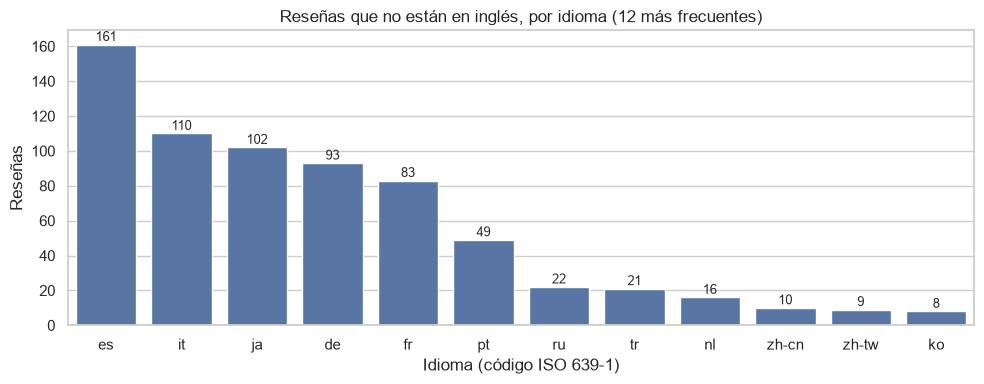


Calificación de las reseñas que no están en inglés:


,count
Rating,
1,9
2,22
3,77
4,246
5,359


In [7]:
import matplotlib.pyplot as plt
from langdetect import detect, DetectorFactory, LangDetectException

DetectorFactory.seed = SEMILLA  # langdetect es aleatorio: la semilla lo hace reproducible

def detectar_idioma(texto):
    """Devuelve el código ISO del idioma del texto, o 'desconocido' si no se puede detectar."""
    try:
        return detect(texto)
    except LangDetectException:
        return "desconocido"

# --- Depuración previa: errores de exportación y duplicados ---
df = df_raw[df_raw["Review"].str.strip() != "#NAME?"].drop_duplicates(subset="Review").copy()
print("Registros tras eliminar #NAME? y duplicados:", len(df))

# --- Detección de idioma ---
df["idioma"] = df["Review"].apply(detectar_idioma)

conteo_idiomas = df["idioma"].value_counts()
print("Reseñas en inglés:", conteo_idiomas.get("en", 0))
print("Reseñas en otros idiomas:", (df["idioma"] != "en").sum(), "en", conteo_idiomas.size - 1, "idiomas")

# --- Gráfica: idiomas distintos del inglés ---
fig, ax = plt.subplots(figsize=(10, 4))
top_idiomas = conteo_idiomas.drop("en").head(12)
sns.barplot(x=top_idiomas.index, y=top_idiomas.values, color="#4C72B0", ax=ax)
ax.set(title="Reseñas que no están en inglés, por idioma (12 más frecuentes)",
       xlabel="Idioma (código ISO 639-1)", ylabel="Reseñas")
for i, v in enumerate(top_idiomas.values):
    ax.text(i, v + 2, str(v), ha="center", fontsize=9)
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "01_idiomas_no_ingles.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Calificación de las reseñas que no están en inglés ---
print("\nCalificación de las reseñas que no están en inglés:")
display(df.loc[df["idioma"] != "en", "Rating"].value_counts().sort_index().to_frame())

**Resultado.** De las 17.976 reseñas únicas válidas, **17.263 (96,0 %) están en inglés** y **713 (4,0 %) en otros 23 idiomas**. Los más frecuentes son español (161), italiano (110), japonés (102), alemán (93) y francés (83). Esta composición es coherente con un destino turístico internacional como Nepal.

**Decisión: se conservan solo las reseñas en inglés.** Las herramientas del proyecto son monolingües: palabras vacías, lematizador `en_core_web_sm`, Word2Vec entrenado sobre el corpus y palabras ancla de las proyecciones semánticas. Una reseña en otro idioma entraría al modelo como un conjunto de palabras raras que solo agregan ruido, y sus términos dispersarían el vocabulario.

**Costo de la decisión.** Se pierden 31 reseñas negativas (9 con calificación 1 y 22 con calificación 2), que representan cerca del 4,5 % de la clase minoritaria del escenario A. Es una pérdida pequeña, pero se registra porque esa clase es la más escasa.

**Limitaciones del detector.**
- `langdetect` es menos confiable con textos muy cortos o mixtos. Por ejemplo, una reseña en hindi escrita con letras latinas («hotel staff bahot achha hai») se clasifica como indonesio.
- Pese a la semilla fija, el resultado puede variar en algún caso límite entre equipos: en una ejecución exploratoria se obtuvieron 17.262 reseñas en inglés, una menos que aquí.

**Trabajo futuro:** traducir las reseñas o usar modelos multilingües (por ejemplo, *embeddings* multilingües) para aprovechar este 4 % del corpus.

## 4. Corpus de trabajo y variable objetivo

Se construye el corpus definitivo (reseñas únicas, válidas y en inglés) y se documenta cuántos registros elimina cada paso de depuración (trazabilidad). Luego se crean las tres definiciones de la variable objetivo propuestas en el anteproyecto:

| Escenario | Definición | Uso |
|:--|:--|:--|
| **A. Binario polar** | positivo = 4–5; negativo = 1–2; se excluye 3 | Principal |
| **B. Tres clases** | negativo = 1–2; neutral = 3; positivo = 4–5 | Complementario |
| **C. Satisfacción plena** | excelente = 5; no excelente = 1–4 | Alternativo |

El corpus depurado se guarda en `data/processed/` para que los notebooks siguientes partan de los mismos datos.

In [5]:
# --- Corpus definitivo ---
df_en = df[df["idioma"] == "en"].drop(columns=["Bubbles", "idioma"]).reset_index(drop=True)
df_en["anio"] = 2000 + df_en["YY"]              # supuesto: YY = año en dos dígitos
df_en["n_palabras"] = df_en["Review"].str.split().str.len()

# --- Variable objetivo: tres escenarios ---
df_en["polaridad_A"] = df_en["Rating"].map({1: "negativo", 2: "negativo", 4: "positivo", 5: "positivo"})  # 3 queda vacío (NaN)
df_en["clase_B"] = pd.cut(df_en["Rating"], bins=[0, 2, 3, 5], labels=["negativo", "neutral", "positivo"])
df_en["excelente_C"] = np.where(df_en["Rating"] == 5, "excelente", "no excelente")

# --- Trazabilidad de la depuración ---
trazabilidad = pd.DataFrame({
    "Paso": ["Archivo original", "Sin registros #NAME?", "Sin duplicados", "Solo inglés"],
    "Registros": [len(df_raw),
                  (df_raw["Review"].str.strip() != "#NAME?").sum(),
                  len(df),
                  len(df_en)],
})
trazabilidad["Eliminados en el paso"] = (-trazabilidad["Registros"].diff()).fillna(0).astype(int)
display(trazabilidad)

# --- Distribución de clases en cada escenario ---
for columna in ["polaridad_A", "clase_B", "excelente_C"]:
    dist = df_en[columna].value_counts().to_frame("Reseñas")
    dist["%"] = (dist["Reseñas"] / dist["Reseñas"].sum() * 100).round(1)
    print(f"\n{columna}  (n = {dist['Reseñas'].sum():,})")
    display(dist)

# --- Guardar resultados ---
df_en.to_csv(RAIZ / "data" / "processed" / "resenas_en_depuradas.csv", index=False)
trazabilidad.to_csv(RUTA_RESULTADOS / "01_trazabilidad_depuracion.csv", index=False)
print("Archivos guardados en data/processed/ y results/")

,Paso,Registros,Eliminados en el paso
0,Archivo original,18074,0
1,Sin registros #NAME?,18071,3
2,Sin duplicados,17976,95
3,Solo inglés,17263,713



polaridad_A  (n = 16,438)


,Reseñas,%
polaridad_A,,
positivo,15788,96.0
negativo,650,4.0



clase_B  (n = 17,263)


,Reseñas,%
clase_B,,
positivo,15788,91.5
neutral,825,4.8
negativo,650,3.8



excelente_C  (n = 17,263)


,Reseñas,%
excelente_C,,
excelente,13154,76.2
no excelente,4109,23.8


Archivos guardados en data/processed/ y results/


**Resultado.** El corpus de trabajo queda con **17.263 reseñas únicas en inglés** (95,5 % del archivo original). La depuración eliminó 811 registros: 3 errores de exportación (`#NAME?`), 95 duplicados y 713 reseñas en otros idiomas. Los 97 duplicados de la auditoría incluían 2 copias de `#NAME?`, que ya se habían eliminado en el paso anterior.

| Escenario | n | Clase minoritaria | Razón de desbalance |
|:--|--:|:--|--:|
| A. Binario polar | 16.438 | negativo: 650 (4,0 %) | ≈ 24 : 1 |
| B. Tres clases | 17.263 | negativo: 650 (3,8 %); neutral: 825 (4,8 %) | ≈ 24 : 1,3 : 1 |
| C. Satisfacción plena | 17.263 | no excelente: 4.109 (23,8 %) | ≈ 3 : 1 |

**Implicaciones para la modelación.**
- En el escenario A, un clasificador que prediga siempre «positivo» alcanzaría 96 % de exactitud sin aprender nada. Por eso las métricas principales serán F1-macro, exactitud balanceada y *recall* de la clase negativa, y se usará `class_weight='balanced'`.
- Las cifras difieren ligeramente de las del anteproyecto (682 → 650 negativas), porque este corpus excluye los registros `#NAME?` y las reseñas que no están en inglés.

## 5. Análisis exploratorio: longitud y composición temporal

Se examinan dos rasgos que pueden sesgar a los clasificadores:
1. **Longitud según la calificación.** Si las reseñas negativas son sistemáticamente más largas, un modelo sensible a la longitud (por ejemplo, BoW con conteos) podría usarla como atajo en lugar del contenido.
2. **Composición de clases por año.** Si la proporción de reseñas negativas cambia en el tiempo, un modelo entrenado con años antiguos podría no generalizar a años recientes (deriva temporal).

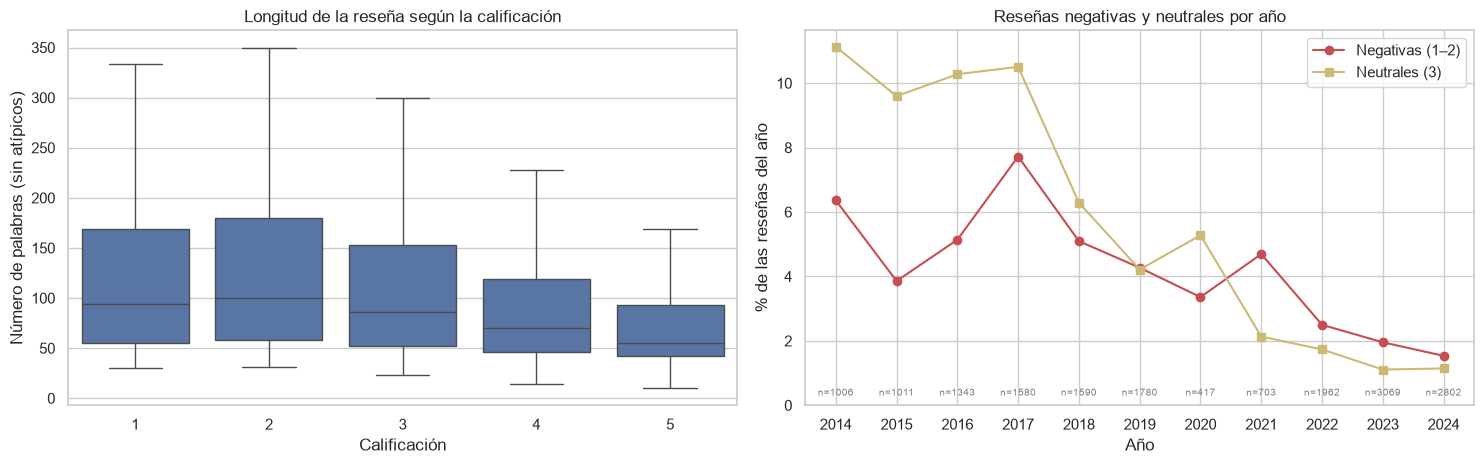

Mediana de palabras por calificación:


Rating,1,2,3,4,5
Mediana,94.0,100.0,86.0,70.0,55.0


Reseñas por año y % por clase:


anio,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Reseñas,1006.0,1011.0,1343.0,1580.0,1590.0,1780.0,417.0,703.0,1962.0,3069.0,2802.0
% negativas,6.4,3.9,5.1,7.7,5.1,4.3,3.4,4.7,2.5,2.0,1.5
% neutrales,11.1,9.6,10.3,10.5,6.3,4.2,5.3,2.1,1.7,1.1,1.1


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# 1. Longitud según la calificación
sns.boxplot(data=df_en, x="Rating", y="n_palabras", showfliers=False, color="#4C72B0", ax=axes[0])
axes[0].set(title="Longitud de la reseña según la calificación",
            xlabel="Calificación", ylabel="Número de palabras (sin atípicos)")

# 2. Porcentaje de reseñas negativas y neutrales por año
composicion = pd.crosstab(df_en["anio"], df_en["clase_B"], normalize="index") * 100
n_por_anio = df_en["anio"].value_counts().sort_index()

axes[1].plot(composicion.index, composicion["negativo"], marker="o", color="#C44E52", label="Negativas (1–2)")
axes[1].plot(composicion.index, composicion["neutral"], marker="s", color="#CCB974", label="Neutrales (3)")
axes[1].set(title="Reseñas negativas y neutrales por año", xlabel="Año",
            ylabel="% de las reseñas del año", ylim=(0, None))
axes[1].set_xticks(composicion.index)
axes[1].legend(loc="upper right")

# Número de reseñas por año, como referencia del tamaño de muestra
for anio, n in n_por_anio.items():
    axes[1].annotate(f"n={n}", (anio, 0.3), ha="center", fontsize=7, color="gray")

plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "01_longitud_y_composicion_anual.png", dpi=150, bbox_inches="tight")
plt.show()

print("Mediana de palabras por calificación:")
display(df_en.groupby("Rating")["n_palabras"].median().to_frame("Mediana").T)

print("Reseñas por año y % por clase:")
resumen_anual = pd.DataFrame({
    "Reseñas": n_por_anio,
    "% negativas": composicion["negativo"].round(1),
    "% neutrales": composicion["neutral"].round(1),
})
display(resumen_anual.T)

**Resultado 1: las reseñas negativas son más largas.** La mediana de palabras disminuye a medida que sube la calificación: 94 (calificación 1), 100 (2), 86 (3), 70 (4) y 55 (5). Quien tuvo una mala experiencia la explica con detalle; quien quedó satisfecho la resume. **Implicación:** la longitud es una señal indirecta de la polaridad. Un clasificador basado en conteos (BoW) podría aprovecharla como atajo, mientras que TF-IDF con normalización L2 y el promedio de vectores Word2Vec la neutralizan. Esto se tendrá en cuenta al comparar las representaciones.

**Resultado 2: deriva temporal.** El porcentaje de reseñas negativas baja de 6,4 % (2014) y 7,7 % (2017) a 1,5 % (2024). Las neutrales caen aún más: de 11,1 % a 1,1 %. El 69,4 % de las reseñas negativas (451 de 650) corresponde al periodo 2014–2019. En 2020 y 2021 la muestra es pequeña (417 y 703 reseñas), lo que es coherente con la caída del turismo durante la pandemia; sus porcentajes son, por tanto, menos estables.

**Implicaciones.**
1. Una partición aleatoria mezcla años con vocabularios y contextos distintos. Como prueba de robustez se hará una **validación temporal**: entrenamiento con 2014–2021 (8.705 reseñas, 498 negativas) y prueba con 2022–2024 (7.733 reseñas, solo 152 negativas).
2. El aumento de la calificación promedio **no se interpreta como mejora del servicio**: el conjunto de datos no permite distinguir entre una mejora real, un cambio en los hoteles reseñados o efectos de la plataforma (moderación, incentivos para publicar).

## 6. Vocabulario del corpus: ley de Zipf y *hapax legomena*

Se tokeniza el texto con una expresión regular simple (minúsculas, solo secuencias de letras, conservando contracciones como *didn't*) y se describe el vocabulario resultante:
- **Tokens:** total de palabras del corpus. **Tipos:** palabras distintas.
- **Ley de Zipf:** en el lenguaje natural, la frecuencia de una palabra es aproximadamente inversamente proporcional a su posición en el ranking de frecuencias (f ∝ 1/rango). En escala logarítmica, esta relación es una recta con pendiente cercana a −1.
- ***Hapax legomena*:** palabras que aparecen una sola vez. Suelen ser errores de digitación, nombres propios o términos muy raros, y no aportan información estadística para el aprendizaje.

Tokens: 1,554,022  |  Tipos: 27,733
Hapax legomena: 13,441 (48.5% del vocabulario)
Las 20 palabras más frecuentes cubren el 33.3% de los tokens


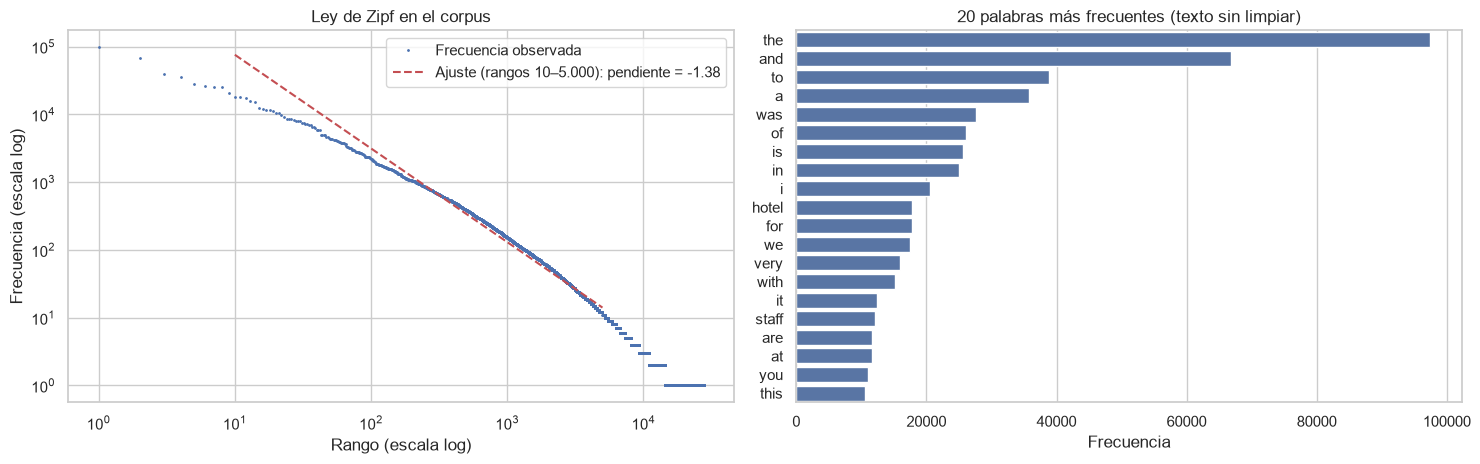

Muestra aleatoria de hapax legomena:
['courious', 'vastness', "place's", 'monetary', 'alto', 'sceptical', 'thsi', 'resport', 'poetically', 'workin', 'ramire', 'machapuchre', 'execllent', 'xoth', 'rotated']


In [10]:
import re
from collections import Counter

def tokenizar_basico(texto):
    """Minúsculas y secuencias de letras; conserva contracciones (didn't, hotel's)."""
    return re.findall(r"[a-z]+(?:'[a-z]+)?", texto.lower())

tokens_por_resena = df_en["Review"].apply(tokenizar_basico)
frecuencias = Counter(token for tokens in tokens_por_resena for token in tokens)

n_tokens = sum(frecuencias.values())
n_tipos = len(frecuencias)
hapax = [palabra for palabra, f in frecuencias.items() if f == 1]
cobertura_top20 = sum(f for _, f in frecuencias.most_common(20)) / n_tokens

print(f"Tokens: {n_tokens:,}  |  Tipos: {n_tipos:,}")
print(f"Hapax legomena: {len(hapax):,} ({len(hapax) / n_tipos:.1%} del vocabulario)")
print(f"Las 20 palabras más frecuentes cubren el {cobertura_top20:.1%} de los tokens")

# --- Ley de Zipf: ajuste lineal en escala log-log, rangos 10 a 5.000 ---
freqs = np.array(sorted(frecuencias.values(), reverse=True))
rangos = np.arange(1, len(freqs) + 1)
tramo = (rangos >= 10) & (rangos <= 5000)
pendiente, intercepto = np.polyfit(np.log10(rangos[tramo]), np.log10(freqs[tramo]), deg=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].loglog(rangos, freqs, ".", markersize=2, color="#4C72B0", label="Frecuencia observada")
axes[0].loglog(rangos[tramo], 10**intercepto * rangos[tramo]**pendiente, "--", color="#C44E52",
               label=f"Ajuste (rangos 10–5.000): pendiente = {pendiente:.2f}")
axes[0].set(title="Ley de Zipf en el corpus", xlabel="Rango (escala log)", ylabel="Frecuencia (escala log)")
axes[0].legend()

top20 = pd.DataFrame(frecuencias.most_common(20), columns=["palabra", "frecuencia"])
sns.barplot(data=top20, y="palabra", x="frecuencia", color="#4C72B0", ax=axes[1])
axes[1].set(title="20 palabras más frecuentes (texto sin limpiar)", xlabel="Frecuencia", ylabel="")

plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "01_zipf_y_frecuencias.png", dpi=150, bbox_inches="tight")
plt.show()

print("Muestra aleatoria de hapax legomena:")
print(pd.Series(hapax).sample(15, random_state=SEMILLA).tolist())

**Resultado.** El corpus tiene **1.554.022 tokens y 27.733 tipos** (palabras distintas).

**Ley de Zipf.** La distribución de frecuencias sigue aproximadamente una recta en escala log-log, como predice la ley de Zipf. La pendiente ajustada (−1,38) es más pronunciada que el valor de referencia (−1): la frecuencia cae más rápido de lo esperado, porque unas pocas palabras concentran gran parte del uso. Esto es coherente con un corpus de dominio especializado, de vocabulario repetitivo (hotel, staff, room). En los extremos, la curva se aparta de la recta: se aplana en las primeras posiciones y forma escalones en la cola, donde muchas palabras comparten frecuencias de 1, 2 o 3.

**Concentración.** Las 20 palabras más frecuentes cubren el 33,3 % de los tokens, y casi todas son **palabras vacías**: artículos, preposiciones y pronombres (*the*, *and*, *to*, *a*, *was*). Solo *hotel* y *staff* tienen contenido propio del dominio. Estas palabras no distinguen una reseña positiva de una negativa; se eliminarán en la normalización.

***Hapax legomena.*** 13.441 palabras (48,5 % del vocabulario) aparecen una sola vez. La muestra aleatoria permite identificar tres tipos:
- **Errores de digitación:** *thsi*, *execllent*, *resport*, *courious*, *workin*.
- **Nombres propios:** *machapuchre* (el monte Machapuchare, cerca de Pokhara), *ramire*.
- **Palabras legítimas pero raras:** *vastness*, *poetically*, *monetary*.

**Implicación.** Casi la mitad del vocabulario no aporta información estadística, porque un modelo no puede aprender nada de una palabra vista una sola vez. Se aplicará un umbral de frecuencia mínima: `min_df` en los vectorizadores y `min_count` en Word2Vec.

"""Normalización y lematización del texto de las reseñas (proyecto LuxuryHotels).

Funciones reutilizadas por todos los notebooks del proyecto.
"""
import re

import spacy

# Palabras de negación: se conservan aunque spaCy las marque como palabras vacías,
# porque invierten la polaridad ("not clean", "never again").
NEGACIONES = {"no", "not", "never", "nor", "neither", "none", "nothing", "nobody", "nowhere", "without"}


def cargar_nlp(modelo="en_core_web_sm"):
    """Carga el modelo de spaCy sin el analizador sintáctico ni el reconocedor de entidades,
    que no se necesitan para lematizar y harían el proceso varias veces más lento."""
    return spacy.load(modelo, disable=["parser", "ner"])


def preparar_texto(texto):
    """Limpieza previa con expresiones regulares, antes de pasar el texto a spaCy."""
    texto = re.sub(r"https?://\S+|www\.\S+", " ", texto)          # URL
    texto = re.sub(r"\S+@\S+", " ", texto)                         # correos
    texto = re.sub(r"([.,!?;:)])(?=[A-Za-z])", r"\1 ", texto)      # "Everyone,If" -> "Everyone, If"
    texto = re.sub(r"(\w)\1{2,}", r"\1\1", texto)                  # "sooooo" -> "soo"
    texto = re.sub(r"\s+", " ", texto)                             # espacios múltiples
    return texto.strip()


def lematizar_corpus(textos, nlp, palabras_extra=(), batch_size=500):
    """Devuelve una lista de textos normalizados: lemas en minúscula, sin palabras vacías
    (excepto negaciones), sin números ni puntuación y sin tokens de una letra."""
    vacias = (nlp.Defaults.stop_words - NEGACIONES) | set(palabras_extra)
    resultado = []
    for doc in nlp.pipe((preparar_texto(t) for t in textos), batch_size=batch_size):
        lemas = []
        for tok in doc:
            if tok.lower_ in ("n't", "nt"):          # didn't -> did + n't -> "not"
                lemas.append("not")
                continue
            if not tok.is_alpha:
                continue
            lema = tok.lemma_.lower()
            if lema in vacias or tok.lower_ in vacias or len(lema) < 2:
                continue
            lemas.append(lema)
        resultado.append(" ".join(lemas))
    return resultado

In [16]:
%load_ext autoreload
%autoreload 2

import sys
import time

if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))
from src.preprocesamiento import cargar_nlp, lematizar_corpus

# --- Normalización (tarda alrededor de 1 minuto) ---
nlp = cargar_nlp()
inicio = time.perf_counter()
df_en["texto_limpio"] = lematizar_corpus(df_en["Review"].tolist(), nlp)
print(f"Tiempo de lematización: {time.perf_counter() - inicio:.0f} s")

# --- Efecto sobre el vocabulario ---
frecuencias_limpio = Counter(t for texto in df_en["texto_limpio"] for t in texto.split())

def resumen_vocabulario(frec):
    return {"Tokens": sum(frec.values()),
            "Tipos (vocabulario)": len(frec),
            "Hapax legomena": sum(1 for f in frec.values() if f == 1)}

efecto = pd.DataFrame({"Texto original": resumen_vocabulario(frecuencias),
                       "Texto normalizado": resumen_vocabulario(frecuencias_limpio)})
efecto["Cambio (%)"] = ((efecto["Texto normalizado"] / efecto["Texto original"] - 1) * 100).round(1)
display(efecto)

print("Negaciones conservadas:", {n: frecuencias_limpio[n] for n in ["not", "no", "never", "nothing", "without"]})
print("Reseñas que quedaron vacías:", (df_en["texto_limpio"].str.len() == 0).sum())

# --- Ejemplo antes / después ---
for i in [3, 10]:
    print(f"\nORIGINAL:    {df_en.loc[i, 'Review'][:250]}")
    print(f"NORMALIZADO: {df_en.loc[i, 'texto_limpio'][:250]}")

# --- Guardar ---
df_en.to_csv(RAIZ / "data" / "processed" / "resenas_en_depuradas.csv", index=False)
efecto.to_csv(RUTA_RESULTADOS / "01_efecto_normalizacion.csv")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Tiempo de lematización: 179 s


,Texto original,Texto normalizado,Cambio (%)
Tokens,1554022,728679,-53.1
Tipos (vocabulario),27733,22931,-17.3
Hapax legomena,13441,11826,-12.0


Negaciones conservadas: {'not': 9478, 'no': 2021, 'never': 763, 'nothing': 598, 'without': 548}
Reseñas que quedaron vacías: 0

ORIGINAL:    Hello Everyone,If you are planning to visit this hotel , please never think about it.. there is many many best hotels with awesome hospitality available in this town .Worst Experience Twice!! I was there for weeding both times.. 6months  for my broth
NORMALIZADO: hello plan visit hotel never think good hotel awesome hospitality available town bad experience twice weed time brother today friend sister experience bad think covid short staff service slow today experience friend family upset staff need training t

ORIGINAL:    My husband and I stayed at Akama for 4 nights. The staff is absolutely fantastic, so kind, helpful and happy! They helped us with all our early morning adventures with taxi ride scheduling, and constantly making sure we were comfortable and satisfied
NORMALIZADO: husband stay akama night staff absolutely fantastic kind helpful h

**Resultado.**

| Medida | Original | Normalizado | Cambio |
|:--|--:|--:|--:|
| Tokens | 1.554.022 | 728.679 | −53,1 % |
| Tipos (vocabulario) | 27.733 | 22.931 | −17,3 % |
| *Hapax legomena* | 13.441 | 11.826 | −12,0 % |

- **Los tokens se reducen a menos de la mitad,** sobre todo por la eliminación de palabras vacías, que concentraban un tercio del texto (bloque 6).
- **El vocabulario se reduce menos (−17,3 %),** por la lematización: *rooms* y *room*, o *stayed* y *stay*, pasan a ser un solo tipo.
- **Los *hapax* se reducen poco (−12,0 %),** porque son en su mayoría errores de digitación y nombres propios, y la lematización no los corrige. Por eso se mantiene la necesidad de un umbral de frecuencia mínima en los modelos.
- **Las negaciones se conservaron:** *not* (9.478), *no* (2.021), *never* (763), *nothing* (598) y *without* (548). *Not* es la sexta palabra más frecuente del corpus normalizado. Ninguna reseña quedó vacía.

**Limitaciones de la normalización** (visibles en los ejemplos):
- La lematización convierte los superlativos en su forma base (*best* → *good*, *worst* → *bad*). Se conserva la polaridad, pero se pierde la **intensidad**.
- Los errores de digitación producen lemas incorrectos: *weeding* (por *wedding*) → *weed*.
- Se eliminan las expresiones que mezclan números y letras (*6months*).
- La lematización con spaCy tardó cerca de 3 minutos. Por eso el texto normalizado se guarda en `data/processed/`, y los notebooks siguientes lo cargan sin repetir el proceso.

## 8. Vocabulario distintivo de las reseñas positivas y negativas

Las palabras más frecuentes (*hotel*, *room*, *staff*) aparecen en ambas clases y no las distinguen. Para identificar el vocabulario **característico** de cada clase (escenario A) se calcula el **logaritmo de la razón de frecuencias relativas** de cada término:

$$\text{LR}(t) = \log_2 \frac{(f_{neg}(t) + 1) \,/\, (N_{neg} + V)}{(f_{pos}(t) + 1) \,/\, (N_{pos} + V)}$$

donde $f$ es la frecuencia del término en cada clase, $N$ el total de tokens de la clase y $V$ el tamaño del vocabulario. Un LR de +3 significa que el término es $2^3 = 8$ veces más frecuente, en proporción, en las reseñas negativas. El +1 (**suavizado de Laplace**) evita dividir por cero cuando un término no aparece en una clase. Solo se consideran términos con al menos 30 apariciones, para no destacar palabras raras.

Se analizan unigramas (palabras sueltas) y bigramas (pares de palabras consecutivas), que capturan expresiones como *not clean*.

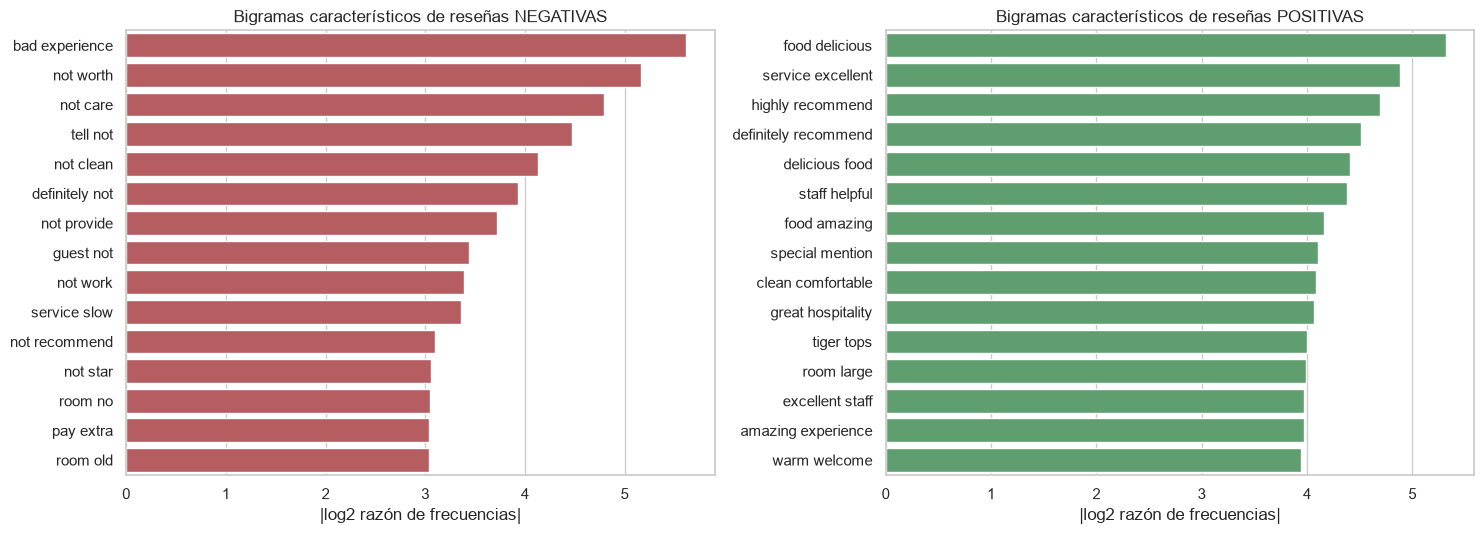

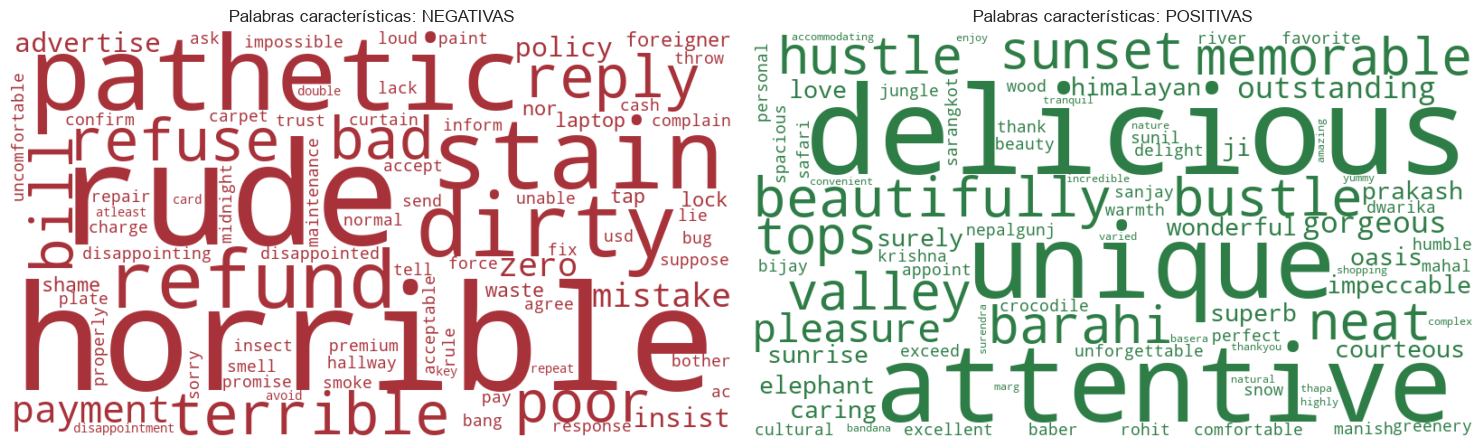

,termino,f_negativo,f_positivo,LR
301,bad experience,38,10,5.62
4432,not worth,30,11,5.16
4286,not care,21,10,4.79
6588,tell not,23,14,4.47
4295,not clean,28,22,4.13
1190,definitely not,21,19,3.93
4385,not provide,17,18,3.72
2479,guest not,17,22,3.44
4430,not work,73,97,3.39
5781,service slow,13,18,3.35


In [19]:
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud

corpus_A = df_en.dropna(subset=["polaridad_A"])
es_negativo = (corpus_A["polaridad_A"] == "negativo").values

def terminos_distintivos(textos, es_negativo, ngramas, min_total=30):
    """Calcula el log2 de la razón de frecuencias relativas (negativo / positivo) con suavizado de Laplace."""
    vectorizador = CountVectorizer(ngram_range=ngramas, min_df=10, token_pattern=r"\S+")
    X = vectorizador.fit_transform(textos)
    f_neg = np.asarray(X[es_negativo].sum(axis=0)).ravel()
    f_pos = np.asarray(X[~es_negativo].sum(axis=0)).ravel()
    V = X.shape[1]
    lr = np.log2(((f_neg + 1) / (f_neg.sum() + V)) / ((f_pos + 1) / (f_pos.sum() + V)))
    tabla = pd.DataFrame({"termino": vectorizador.get_feature_names_out(),
                          "f_negativo": f_neg, "f_positivo": f_pos, "LR": lr})
    return tabla[tabla["f_negativo"] + tabla["f_positivo"] >= min_total]

unigramas = terminos_distintivos(corpus_A["texto_limpio"], es_negativo, (1, 1))
bigramas = terminos_distintivos(corpus_A["texto_limpio"], es_negativo, (2, 2))

# --- Figura 1: bigramas distintivos ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (titulo, datos, color) in zip(axes, [
        ("Bigramas característicos de reseñas NEGATIVAS", bigramas.nlargest(15, "LR"), "#C44E52"),
        ("Bigramas característicos de reseñas POSITIVAS", bigramas.nsmallest(15, "LR"), "#55A868")]):
    sns.barplot(data=datos, y="termino", x=datos["LR"].abs(), color=color, ax=ax)
    ax.set(title=titulo, xlabel="|log2 razón de frecuencias|", ylabel="")
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "01_bigramas_distintivos.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Figura 2: nubes de palabras ponderadas por LR, con color fijo ---
def color_fijo(color):
    """Devuelve una función que pinta todas las palabras de la nube del mismo color."""
    return lambda *args, **kwargs: color

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (titulo, datos, color) in zip(axes, [
        ("Palabras características: NEGATIVAS", unigramas.nlargest(80, "LR"), "#A8323A"),
        ("Palabras características: POSITIVAS", unigramas.nsmallest(80, "LR"), "#2E7D46")]):
    pesos = dict(zip(datos["termino"], datos["LR"].abs()))
    nube = WordCloud(width=800, height=450, background_color="white",
                     color_func=color_fijo(color), random_state=SEMILLA).generate_from_frequencies(pesos)
    ax.imshow(nube, interpolation="bilinear")
    ax.set_title(titulo)
    ax.axis("off")
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "01_nubes_distintivas.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Tabla para revisión ---
display(bigramas.nlargest(15, "LR").round(2))
bigramas.to_csv(RUTA_RESULTADOS / "01_bigramas_distintivos.csv", index=False)